In [1]:
import numpy as np
import pandas as pd
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
config = read_config(
   '/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/config_n2o.yaml')
analyze_year=True
# years=[2007,2008,2009,2010,2011,2012,2013,2014,2015]
years = [year for year in range(2007, 2017)]
glac_threshold=0.4




NameError: name 'xr' is not defined

In [2]:
# Set up analysis dataframe
dataset = ChunkLoader(years,config=config)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/Final_results/2007_all.parquet', 2008: '/wolke_scratch/dnikolo/Final_results/2008_all.parquet', 2009: '/wolke_scratch/dnikolo/Final_results/2009_all.parquet', 2010: '/wolke_scratch/dnikolo/Final_results/2010_all.parquet', 2011: '/wolke_scratch/dnikolo/Final_results/2011_all.parquet', 2012: '/wolke_scratch/dnikolo/Final_results/2012_all.parquet', 2013: '/wolke_scratch/dnikolo/Final_results/2013_all.parquet', 2014: '/wolke_scratch/dnikolo/Final_results/2014_all.parquet', 2015: '/wolke_scratch/dnikolo/Final_results/2015_all.parquet', 2016: '/wolke_scratch/dnikolo/Final_results/2016_all.parquet'}


In [24]:
glac = dataset.glac_chunk
cloud = dataset.cloud_chunk

In [26]:
(cloud[abs(cloud["avg_lat"])<60].avg_ctp<630).value_counts(normalize=True)

avg_ctp
True     0.578144
False    0.421856
Name: proportion, dtype: float64

In [27]:
(glac[abs(glac["avg_lat"])<60].avg_ctp<630).value_counts(normalize=True)

avg_ctp
True     0.911152
False    0.088848
Name: proportion, dtype: float64

In [2]:
import xarray as xr
import numpy as np

In [2]:
remapped_data = xr.load_dataset("/wolke_scratch/dnikolo/ICON_Data/COSP_sample/test01_cosp_ml_20080902T000000Z_remap.nc")

In [22]:
cosp_output = xr.load_dataset("/wolke_scratch/dnikolo/ICON_Data/COSP_sample/test01_cosp_ml_20080902T000000Z.nc")

In [23]:
cosp_output

<xarray.Dataset>
Dimensions:                          (ncells: 20480, vertices: 3, time: 1)
Coordinates:
    clon                             (ncells) float32 0.6283 0.6283 ... 0.2156
    clat                             (ncells) float32 0.9184 0.9405 ... -0.6939
  * time                             (time) float64 2.008e+07
Dimensions without coordinates: ncells, vertices
Data variables: (12/15)
    clon_bnds                        (ncells, vertices) float32 0.6606 ... 0....
    clat_bnds                        (ncells, vertices) float32 0.9293 ... -0...
    modis_cloud_fraction_total       (time, ncells) float64 100.0 5.0 ... 100.0
    modis_cloud_fraction_water       (time, ncells) float64 100.0 5.0 ... 100.0
    modis_cloud_fraction_ice         (time, ncells) float64 0.0 0.0 ... 0.0 0.0
    modis_cloud_fraction_low         (time, ncells) float64 100.0 5.0 ... 0.0
    ...                               ...
    modis_optical_thickness_water    (time, ncells) float64 56.66 ... 37.22
    modis_optical_thickness_ice      (time, ncells) float64 nan nan ... nan nan
    modis_cloud_particle_size_water  (time, ncells) float64 9.213e-06 ... 1.0...
    modis_cloud_particle_size_ice    (time, ncells) float64 nan nan ... nan nan
    modis_liquid_water_path          (time, ncells) float64 0.348 ... 0.2634
    modis_ice_water_path             (time, ncells) float64 nan nan ... nan nan
Attributes:
    CDI:                  Climate Data Interface version 1.8.3rc (http://mpim...
    Conventions:          CF-1.6
    number_of_grid_used:  5
    grid_file_uri:        http://icon-downloads.mpimet.mpg.de/grids/public/ic...
    uuidOfHGrid:          6dffb27e-c162-11e6-bde4-f3bd241f4de0
    institution:          Max Planck Institute for Meteorology/Deutscher Wett...
    title:                ICON simulation
    source:               Unknown@Unknown
    history:              /capstor/store/cscs/userlab/lp88/rvella/git/icon-ha...
    references:           see MPIM/DWD publications
    comment:              Ryan Vella, ETHZ (rvella) on nid005227 (Linux 5.14....

In [11]:
cosp_output.close()

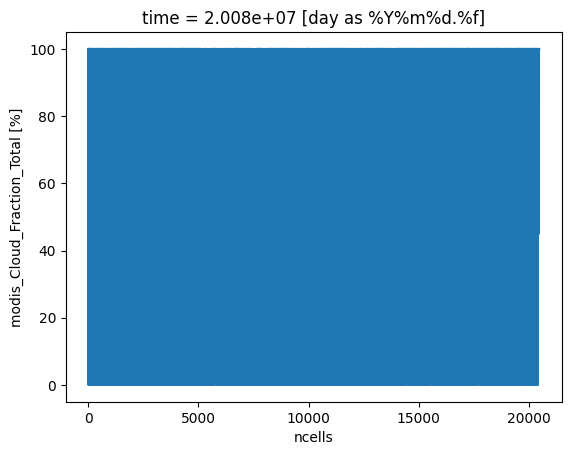

In [ ]:
cosp_output.modis_cloud_fraction_total.isel(time=0)

In [4]:
# cosp_output.modis_cloud_fraction_total.plot()

In [5]:
# cosp_output

In [20]:
#%% Libraries
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import scipy.interpolate
from matplotlib.ticker import ScalarFormatter
def plot_surface_temp_map(path):
    # 1. Load Data
    try:
        ds = xr.open_dataset(path)
    except FileNotFoundError:
        print(f"File not found: {path}")
        return

    # 2. Calculate Time Mean (Daily Mean)
    # Averaging over the 'time' dimension
    # ts_data = ds['ts'].mean(dim='time') # Daily mean
    ts_data = ds.modis_cloud_fraction_total.isel(time=0) # first time step (00:00)

    # Convert Kelvin to Celsius
    ts_mean_c = ts_data
    
    # 3. Extract Coordinates (Unstructured Grid)
    # ICON usually stores lon/lat in radians
    if 'clon' in ds and 'clat' in ds:
        lon = np.degrees(ds['clon'].values)
        lat = np.degrees(ds['clat'].values)
    else:
        # Fallback if coordinates are named differently (common in some post-processed files)
        print("Warning: 'clon'/'clat' not found. Checking for 'lon'/'lat'...")
        lon = ds['lon'].values
        lat = ds['lat'].values

    # 4. Interpolate to Regular Grid for Plotting
    # Define a regular grid (0.5 degree resolution)
    lat_grid = np.linspace(-90, 90, 360)
    lon_grid = np.linspace(-180, 180, 720)
    lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)

    print("Interpolating unstructured data to regular grid...")
    # Use Linear interpolation
    ts_interp = scipy.interpolate.griddata(
        (lon.flatten(), lat.flatten()), 
        ts_mean_c.values.flatten(), 
        (lon_mesh, lat_mesh), 
        method='linear'
    )

    # 5. Plotting
    fig = plt.figure(figsize=(12, 8))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Plot contours
    # Adjust vmin/vmax based on your expected range, or let matplotlib decide
    mesh = ax.pcolormesh(
        lon_mesh, lat_mesh, ts_interp, 
        transform=ccrs.PlateCarree(), 
        cmap='RdYlBu_r', # Red for hot, Blue for cold
        shading='auto'
    )

    # Add Coastlines and Grid
    ax.coastlines()
    ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, alpha=0.3)

    # Colorbar
    # cbar = plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.05, fraction=0.05)
    # cbar.set_label(r'Surface Temperature ($^\circ$C)')

    # Titles
    ax.set_title('Daily Mean Surface Temperature', fontsize=14)
    plt.suptitle(f'Source: {path.split("/")[-1]}', fontsize=10, y=0.95)

    print("Plot generated.")
    plt.show()



Interpolating unstructured data to regular grid...
Plot generated.


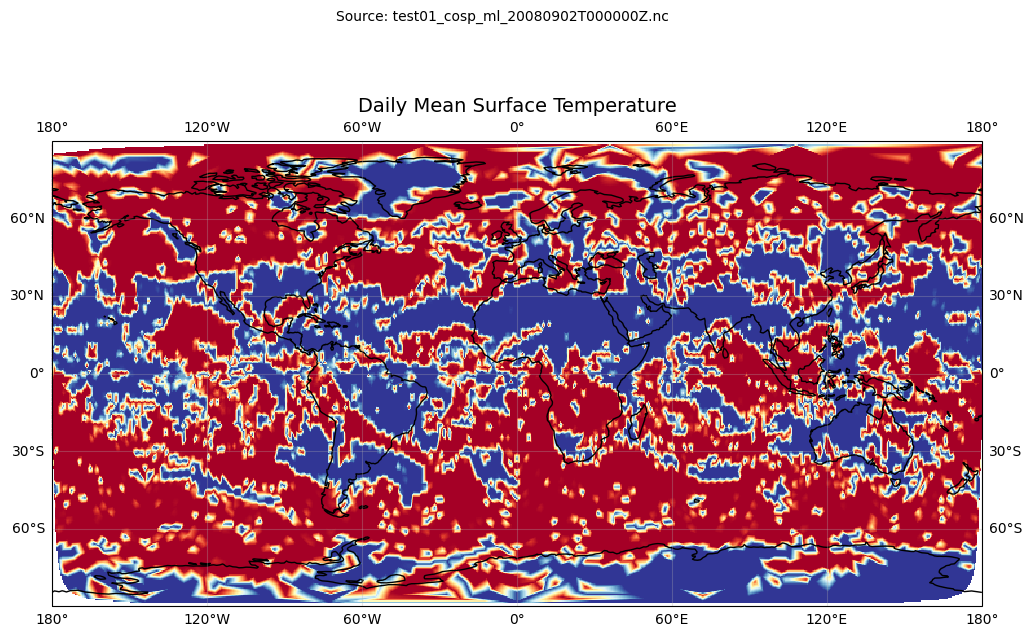

In [21]:
# --- Run the function ---

plot_surface_temp_map("/wolke_scratch/dnikolo/ICON_Data/COSP_sample/test01_cosp_ml_20080902T000000Z.nc")

In [ ]:
np.isnan(cosp_output.modis_cloud_fraction_total.values).all()

False